In [1]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
%pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS
import re

Note: you may need to restart the kernel to use updated packages.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
data = pd.read_csv(r'C:\Users\LN\Documents\Jedha\Projets\NORTH_FACE\Helene\data\sample_clean.csv')

In [3]:
data.head()

,id,products,advantages,description_text,details,fabric,weight,country
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico
1,2,active sport boxer briefs,skinning up glory requires enough movement wit...,active sport boxer briefs - skinning up glory ...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",60 g 2.1 oz,israel
2,3,active sport briefs,these superbreathable no-fly briefs are the mi...,active sport briefs - these superbreathable no...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",49 g 1.7 oz,israel
3,4,alpine guide pants,"skin in, climb ice, switch to rock, traverse a...","alpine guide pants - skin in, climb ice, switc...",durable stretch-woven polyester 47% recycled w...,7.6-oz 90-denier 92% polyester 47% recycled /8...,597 g 20.7 oz,vietnam
4,5,alpine wind jkt,"on high ridges, steep ice and anything alpine,...","alpine wind jkt - on high ridges, steep ice an...","lightweight, breathable polyester ripstop fabr...",shell 1.3-oz 20-denier 100% polyester ripstop....,331 g 11.5 oz,china


In [4]:
type(data)

pandas.core.frame.DataFrame

In [5]:
data['products'].tolist()

['active classic boxers',
 'active sport boxer briefs',
 'active sport briefs',
 'alpine guide pants',
 'alpine wind jkt',
 'ascensionist jkt',
 'atom',
 'print banded betina btm',
 'baby micro d-luxe cardigan',
 'baby sun bucket hat',
 'baby sunshade top',
 'baggies shorts',
 'beach bucket',
 'better sweater jkt',
 'borderless shorts-11 in.',
 'borderless shorts-7 in.',
 'bucket hat',
 'cap 1 bottoms',
 'cap 1 boxer briefs',
 'cap 1 graphic t-shirt',
 'cap 1 t-shirt',
 'cap 2 t-shirt',
 'cap 2 zip neck',
 'cap 3 zip neck',
 'cap 4 bottoms',
 'city by the sea t-shirt',
 'compound cargo pants',
 'compound cargo pants',
 'continental shorts',
 'cotton board shorts',
 'crosstown',
 'custodian pants',
 'deep wading jkt',
 'delivery shorts',
 'down sweater vest',
 'dragoons t-shirt',
 'duck pants',
 'elias fz sweatshirt',
 'elias sweatshirt',
 'fezzman shirt',
 'fish frenzy t-shirt',
 'freewheeler',
 'gi ii pants',
 'gi ii shorts',
 "girl's boardie capris",
 "girl's boardie shorts",
 "girl'

In [6]:
cols = ["products", 'advantages', 'details', 'fabric', 'weight', 'country', 'description_text']
[data[c].str.lower() for c in cols]

[0          active classic boxers
 1      active sport boxer briefs
 2            active sport briefs
 3             alpine guide pants
 4                alpine wind jkt
                  ...            
 495                cap 2 bottoms
 496                   cap 2 crew
 497               all-time shell
 498        all-wear cargo shorts
 499              all-wear shorts
 Name: products, Length: 500, dtype: object,
 0      there's a reason why our boxers are a cult fav...
 1      skinning up glory requires enough movement wit...
 2      these superbreathable no-fly briefs are the mi...
 3      skin in, climb ice, switch to rock, traverse a...
 4      on high ridges, steep ice and anything alpine,...
                              ...                        
 495    cut loose from the maddening crowds and search...
 496    this crew takes the edge off fickle weather. i...
 497    no need to use that morning times as an umbrel...
 498    all-wear cargo shorts bask in the glory of swe...
 

In [7]:
data['text'] = data['products'] + ' ' + data['advantages']

In [8]:
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico,active classic boxers there's a reason why our...


In [9]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['text'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

# # Ajouter des stop words personnalisés
# nlp.Defaults.stop_words.update({"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"})

# # Appliquer les modifications au vocabulaire
# for word in {"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"}:
#     nlp.vocab[word].is_stop = True

Tokens: ['active', 'classic', 'boxers', 'there', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'the', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'an', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'inseam', '(', 'size', 'm', ')', 'is', '4', '1/2', '"', '.', 'recyclable', 'through', 'the', 'common', 'threads', 'recycling', 'program', '.']
------------
Lemma: ['active', 'classic', 'boxer', 'there', 'be', 'a', 'reason', 'why', 'our', 'boxer', 'be', 'a', 'cult

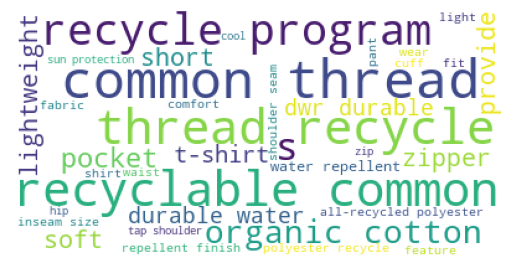

In [10]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud
from spacy.lang.en.stop_words import STOP_WORDS
from spacy.lang.char_classes import HYPHENS
from spacy.util import compile_infix_regex

infixes = [x for x in nlp.Defaults.infixes if HYPHENS not in x]
nlp.tokenizer.infix_finditer = compile_infix_regex(infixes).finditer

text = " ".join(data['text'].astype(str))
text = re.sub(r"<[^>]+>", " ", text) # replace html
# Garder uniquement les lettres anglaises, espaces et tirets
text = re.sub(r"[^a-z\s-]+", " ", text.lower())

# Garder uniquement les tirets entre deux lettres
text = re.sub(r"(?<![a-z])-|-(?![a-z])", " ", text)

# Normaliser les espaces
text = re.sub(r"\s+", " ", text).strip()

doc = nlp(text)
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
lemma

cloud = wordcloud.WordCloud(
    regexp=r"[\w'-]+", # MODIF : garde les mots avec tiret
    stopwords=STOP_WORDS, 
    collocations=True, # remove bigrams
    min_font_size=7,
    background_color="white", 
    colormap="viridis"
).generate(" ".join(lemma)) # remove stopwords

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [11]:
data.head()

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico,active classic boxers there's a reason why our...
1,2,active sport boxer briefs,skinning up glory requires enough movement wit...,active sport boxer briefs - skinning up glory ...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",60 g 2.1 oz,israel,active sport boxer briefs skinning up glory re...
2,3,active sport briefs,these superbreathable no-fly briefs are the mi...,active sport briefs - these superbreathable no...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",49 g 1.7 oz,israel,active sport briefs these superbreathable no-f...
3,4,alpine guide pants,"skin in, climb ice, switch to rock, traverse a...","alpine guide pants - skin in, climb ice, switc...",durable stretch-woven polyester 47% recycled w...,7.6-oz 90-denier 92% polyester 47% recycled /8...,597 g 20.7 oz,vietnam,"alpine guide pants skin in, climb ice, switch ..."
4,5,alpine wind jkt,"on high ridges, steep ice and anything alpine,...","alpine wind jkt - on high ridges, steep ice an...","lightweight, breathable polyester ripstop fabr...",shell 1.3-oz 20-denier 100% polyester ripstop....,331 g 11.5 oz,china,"alpine wind jkt on high ridges, steep ice and ..."


In [12]:
from collections import Counter; Counter(lemma).most_common()

[('recycle', 413),
 ('pocket', 361),
 ('recyclable', 332),
 ('thread', 331),
 ('common', 329),
 ('program', 328),
 ('s', 313),
 ('polyester', 247),
 ('organic', 190),
 ('fabric', 189),
 ('cotton', 178),
 ('soft', 157),
 ('short', 151),
 ('durable', 149),
 ('zipper', 144),
 ('water', 141),
 ('dry', 140),
 ('nylon', 140),
 ('fit', 132),
 ('lightweight', 129),
 ('t-shirt', 128),
 ('spandex', 121),
 ('oz', 120),
 ('feature', 120),
 ('seam', 120),
 ('pant', 117),
 ('provide', 116),
 ('shoulder', 110),
 ('inseam', 104),
 ('breathable', 104),
 ('finish', 103),
 ('blend', 99),
 ('shirt', 95),
 ('dwr', 92),
 ('strap', 91),
 ('sun', 90),
 ('repellent', 89),
 ('hem', 89),
 ('size', 86),
 ('layer', 84),
 ('merino', 83),
 ('comfort', 82),
 ('protection', 81),
 ('neck', 78),
 ('fly', 77),
 ('stretch', 75),
 ('light', 75),
 ('sleeve', 74),
 ('cuff', 73),
 ('skin', 72),
 ('t', 72),
 ('include', 72),
 ('long', 72),
 ('all-recycled', 68),
 ('cool', 66),
 ('pack', 66),
 ('waistband', 65),
 ('waist', 65),

In [13]:
pd.set_option("display.max_rows", None)      # show all rows
pd.set_option("display.max_colwidth", None)  # no column truncation

In [14]:
data[["products", "advantages"]].drop_duplicates(subset="products")
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,"active classic boxers there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program."


In [15]:
def lemma(doc):
    return "".join(token.lemma_ + token.whitespace_ for token in doc).strip()

keywords = [
    # 'bag',
    # 'baggage',
    # # 'belt',
    # 'boot',
    # 'bottom | btm',
    # 'boxer',
    # 'bra',
    # 'brief',
    # # 'cap',
    # 'capri',
    # 'cardigan',
    # 'daypack',
    # 'divider',
    # 'dress',
    # 'duffle',
    # 'glove',
    # 'hat',
    # 'hoody',
    # 'jeans-',
    # 'jacket | jkt', 
    # # 'pack',
    # 'pant',
    # 'polo',
    # 'poster',
    # 'pullover | p/o',
    # 'rashguard',
    # 'short',
    # 'skirt',
    # 'sneaker',
    # 'sock',
    # 'storage locker',
    # 'sweater',
    # 'sweatshirt',
    # # 'shell',
    # 'tank',
    # 'top',
    # 'tote',
    # 't-shirt | t-shir',
    # 'shirt',
    # 'tight',
    # 'trench coat',
    # 'trunk',
    # 'underwear',
    # 'vest',
    # 'visor',
    # 'wader',
    'zip neck'
    ]
data["lemma"] = [lemma(doc) for doc in docs]
keywords_lemma = [lemma(doc) for doc in nlp.pipe(keywords)]
data["product_type"] = ""

for groupe in keywords:
    treatment = [
        re.escape(word) + (r"s?" if word[-1].isalpha() and not word.endswith("s") else "")
        for word in map(str.strip, groupe.split("|")) if word
    ]
    pattern = r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)" if treatment else r"(?!)"
    search = data["lemma"].str.contains(pattern, case=False, na=False)
    data.loc[search, "product_type"] += groupe.split("|")[0].strip() + ", "

data["product_type"] = data["product_type"].str.removesuffix(", ")
search = data["product_type"] != ""
not_found = data.loc[~search, ["lemma", "products", "advantages"]]
print(f"{len(not_found)} documents sans mot-clé sur {len(data)}")
not_found

495 documents sans mot-clé sur 500


,lemma,products,advantages
0,"active classic boxer therebe a reason why our boxer be a cult favorite - they keep their cool, especially in sticky situation. the quick-dry, lightweight underwear take up minimal space in a travel pack. an expose, brush waistband offer next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. make of 3.7-oz 100% recycled polyester with moisture-wicke performance. inseam (size m) be 4 1/2"". recyclable through the common thread recycle program.",active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program."
1,"active sport boxer brief skin up glory require enough movement without your boxer decide to poach their own route. the form-fit active sport boxer brief be make from breathable 93% polyester (71% recycle) fabric thatbe fast-wicke, dry quickly and have 7% spandex for stretch; the seamless waistband and soft leg edge willnot roll or bind. the gusseted, flat-sew 6"" inseam (size m) be offset to prevent inner-thigh chafe. fly-free with a smooth front panel. recyclable through the common thread recycle program.",active sport boxer briefs,"skinning up glory requires enough movement without your boxers deciding to poach their own route. the form-fitting active sport boxer briefs are made from breathable 93% polyester (71% recycled) fabric that's fast-wicking, dries quickly and has 7% spandex for stretch; the seamless waistband and soft leg edges won't roll or bind. the gusseted, flat-sewn 6"" inseam (size m) is offset to prevent inner-thigh chafe. fly-free with a smooth front panel. recyclable through the common threads recycling program."
2,"active sport brief these superbreathable no-fly brief be the minimalist's choice for high-octane endeavor. make from a blend of fast-wicke, quick-dry 93% polyester (71% recycle) and 7% spandex that have both stretch-mesh (for support) and open mesh (for cool airflow). soft edging at the leg opening and a seamless waist willnot roll or create friction against layer. with a smooth front panel for opacity. recyclable through the common thread recycle program.",active sport briefs,"these superbreathable no-fly briefs are the minimalist's choice for high-octane endeavors. made from a blend of fast-wicking, quick-drying 93% polyester (71% recycled) and 7% spandex that has both stretch-mesh (for support) and open mesh (for cooling airflow). soft edging at the leg openings and a seamless waist won't roll or create friction against layers. with a smooth front panel for opacity. recyclable through the common threads recycling program."
3,"alpine guide pant skin in, climb ice, switch to rock, traverse a knife-edge ridge and boogie back down - these durable, weather-resistant and breathable soft-shell pant keep stride on every mountain endeavor. the midweight stretch-weave polyester willnot restrict your move, and the brush interior maintain next-to-skin comfort. a 2-way zipper fly keep thing easy with a harness on, and the gussete, zippered cuff have 2-position snap and tie-down loop. with water-resistant zippered pocket: two front, two thigh, one back hip. recyclable through the common thread recycle program.",alpine guide pants,"skin in, climb ice, switch to rock, traverse a knife-edge ridge and boogie back down - these durable, weather-resistant and breathable soft-shell pants keep stride on every mountain endeavor. the midweight stretch-woven polyester won't restrict your moves, and the brushed interior maintains next-to-skin comfort. a 2-way zippered 

In [16]:
data[['lemma', 'product_type']]

,lemma,product_type
0,"active classic boxer therebe a reason why our boxer be a cult favorite - they keep their cool, especially in sticky situation. the quick-dry, lightweight underwear take up minimal space in a travel pack. an expose, brush waistband offer next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. make of 3.7-oz 100% recycled polyester with moisture-wicke performance. inseam (size m) be 4 1/2"". recyclable through the common thread recycle program.",
1,"active sport boxer brief skin up glory require enough movement without your boxer decide to poach their own route. the form-fit active sport boxer brief be make from breathable 93% polyester (71% recycle) fabric thatbe fast-wicke, dry quickly and have 7% spandex for stretch; the seamless waistband and soft leg edge willnot roll or bind. the gusseted, flat-sew 6"" inseam (size m) be offset to prevent inner-thigh chafe. fly-free with a smooth front panel. recyclable through the common thread recycle program.",
2,"active sport brief these superbreathable no-fly brief be the minimalist's choice for high-octane endeavor. make from a blend of fast-wicke, quick-dry 93% polyester (71% recycle) and 7% spandex that have both stretch-mesh (for support) and open mesh (for cool airflow). soft edging at the leg opening and a seamless waist willnot roll or create friction against layer. with a smooth front panel for opacity. recyclable through the common thread recycle program.",
3,"alpine guide pant skin in, climb ice, switch to rock, traverse a knife-edge ridge and boogie back down - these durable, weather-resistant and breathable soft-shell pant keep stride on every mountain endeavor. the midweight stretch-weave polyester willnot restrict your move, and the brush interior maintain next-to-skin comfort. a 2-way zipper fly keep thing easy with a harness on, and the gussete, zippered cuff have 2-position snap and tie-down loop. with water-resistant zippered pocket: two front, two thigh, one back hip. recyclable through the common thread recycle program.",
4,"alpine wind jkt on high ridge, steep ice and anything alpine, this jacket serve as a true ""good of all world"" staple. it excel as a stand-alone shell for blustery rock climb, cool-weather trail run and high-output ski tour. and then, when condition have you ice and alpine climbing, it function as a lightly insulate windshirt on the approach, as well as a frictionless midlayer when itbe time to bundle up and tie-in. the polyester ripstop shell with a deluge dwr (durable water repellent) treatment shed snow and block wind, while the smooth, lightly brush hang mesh liner wick moisture, dry fast, and donot bind to your baselayer. superlight stretch-weave underarm panel enhance breathability and allow for unimpaired arm motion, and the two hand pocket close with zipper. a drawcord hem, elastic cuff, a heat-transfer reflective logo and a regular-coil, center-front zipper with dwr finish round out the feature. update this season for an improve fit. recyclable through the common thread recycle program.",
5,"ascensionist jkt our most technical soft shell for full-on mountain pursuit strike the alpinist's balance between protection and minimalism. the dense 2-way-stretch polyester double weave, with stitchless seam, have exceptional water- and wind-resistance, a rapid dry time and superb breathability. par-down detail provide everything you need and nothing more: a 3-way-adjustable, helmet-compatible hood; a reverse-coil center-front zipper with a dwr (durable water repellent) finish; large external handwarmer pocket (with zipper garage) that be place above the harness-line; an internal security pocket; articulated arm; self-fabic cuff tab; a drawcord hem. recyclable through the common thread recycle program.",
6,"atom a multitasker's cloud nine, the atom play the part of courier bag, daypack and carry-on. its teardrop shape provide the support of a daypack by position

La liste est très bruitée. On va se recentrer sur les produits maintenant que nous les connaissons.

In [17]:
data['text'] = data['products']


In [18]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['text'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

# # Ajouter des stop words personnalisés
# nlp.Defaults.stop_words.update({"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"})

# # Appliquer les modifications au vocabulaire
# for word in {"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"}:
#     nlp.vocab[word].is_stop = True

Tokens: ['active', 'classic', 'boxers']
------------
Lemma: ['active', 'classic', 'boxer']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['active', 'sport', 'boxer', 'briefs']
------------
Lemma: ['active', 'sport', 'boxer', 'brief']
------------
Indices: [0, 1, 2, 3]
------------
Alpha Numeric: [True, True, True, True]
------------
Numbers: [False, False, False, False]
Tokens: ['active', 'sport', 'briefs']
------------
Lemma: ['active', 'sport', 'brief']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['alpine', 'guide', 'pants']
------------
Lemma: ['alpine', 'guide', 'pant']
------------
Indices: [0, 1, 2]
------------
Alpha Numeric: [True, True, True]
------------
Numbers: [False, False, False]
Tokens: ['alpine', 'wind', 'jkt']
------------
Lemma: ['alpine', 'wind', 'jkt']
------------
Indices: [0, 1, 2]
------------

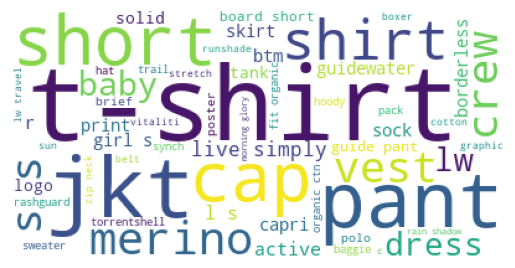

In [19]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud
from spacy.lang.en.stop_words import STOP_WORDS
from spacy.lang.char_classes import HYPHENS
from spacy.util import compile_infix_regex

infixes = [x for x in nlp.Defaults.infixes if HYPHENS not in x]
nlp.tokenizer.infix_finditer = compile_infix_regex(infixes).finditer

text = " ".join(data['text'].astype(str))
text = re.sub(r"<[^>]+>", " ", text) # replace html
# Garder uniquement les lettres anglaises, espaces et tirets
text = re.sub(r"[^a-z\s-]+", " ", text.lower())

# Garder uniquement les tirets entre deux lettres
text = re.sub(r"(?<![a-z])-|-(?![a-z])", " ", text)

# Normaliser les espaces
text = re.sub(r"\s+", " ", text).strip()

doc = nlp(text)
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
lemma

cloud = wordcloud.WordCloud(
    regexp=r"[\w'-]+", # MODIF : garde les mots avec tiret
    stopwords=STOP_WORDS, 
    collocations=True, # remove bigrams
    min_font_size=7,
    background_color="white", 
    colormap="viridis"
).generate(" ".join(lemma)) # remove stopwords

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [20]:
data["products"].drop_duplicates()
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text,lemma,product_type
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,active classic boxers,"active classic boxer therebe a reason why our boxer be a cult favorite - they keep their cool, especially in sticky situation. the quick-dry, lightweight underwear take up minimal space in a travel pack. an expose, brush waistband offer next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. make of 3.7-oz 100% recycled polyester with moisture-wicke performance. inseam (size m) be 4 1/2"". recyclable through the common thread recycle program.",


In [21]:
def lemma(doc):
    return "".join(token.lemma_ + token.whitespace_ for token in doc).strip()

keywords = [
    'backpack | crosstown | atom',
    'bag | minimass | half mass | critical mass',
    'baggage',
    'belt',
    'boot',
    'bottom | btm',
    'boxer',
    'bra',
    'brief',
    'beach bucket',
    'cami', # caraco
    # 'cap',
    'cardigan | versatiliti cardi',
    'crew',
    'divider',
    'dress',
    'duffle | duffel',
    'glove',
    'hat',
    'hip chest pack',
    'hip pack',
    'hipster',
    'hoody',
    r"jeans | re:jeans?-\w+", # rechercher un mot en début de chaîne de caractères
    'jacket | jkt', 
    'carryon| mlc',
    # 'pack',
    'mat | remat',
    'pant | capri | long haul runner | double haul',
    'pocket pack',
    'polo',
    'poster | traverse auguille d\'entreves',
    'pullover | p/o | cap 2 v-neck | synch snap-t',
    'rashguard',
    'skirt',
    'sneaker',
    'sock',
    'storage locker',
    'sweater',
    'sweatshirt',
    'shell',
    'shirt',  
    'bikini',
    'tankini',
    'short | shortie',
    'shoulder bag  | daily grind',
    't-back',
    't-shirt | t-shir | cap 1 graphic tee | s/s stretch t | versatili-tee | versatiliti tee	| simply organic tee | organic cotton under tee | l/s gravi-tee | vitaliti vee',
    'tank',
    'tight',
    'top | solid bibiana 1 piece | cap 2 cap sleeve | cap 1 scoop',
    'tote',
    'travel courier',
    'travel pack',
    'travel sling',
    'trench coat',
    'trunk',
    'tunic',
    # 'underwear',
    'vest | aravis 1/4 zip',
    'velocity cap', # casquette de cycliste (avoid cap like capilene)
    'visor | brim',
    'wader | riverwalker | watermaster',
    'waterproof pack | stormfront pack',
    'wheeled bag | freewheel',
    'wrap', # écharpe
    'zip neck'
    ]
data["lemma"] = [lemma(doc) for doc in docs]
keywords_lemma = [lemma(doc) for doc in nlp.pipe(keywords)]
data["product_type"] = ""

# pour utiliser des regex
for groupe in keywords:
    if " | re:" in groupe:
        treatment = [groupe.split(" | re:", 1)[1]]
    else:
        treatment = [
            word + (r"s?" if word[-1].isalpha() and not word.endswith("s") else "")
            for word in map(str.strip, groupe.split("|")) if word
        ]
    pattern = r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)" if treatment else r"(?!)"
    search = data["lemma"].str.contains(pattern, na=False)
    data.loc[search, "product_type"] += groupe.split("|")[0].strip() + ", "

data["product_type"] = data["product_type"].str.removesuffix(", ")
search = data["product_type"] != ""
not_found = data.loc[~search, ["lemma", "products"]]
print(f"{len(not_found)} documents sans mot-clé sur {len(data)}")
not_found

9 documents sans mot-clé sur 500


,lemma,products
65,synch marsupial,synch marsupial
353,single shot,single shot
373,pique fleece 1/4 zip,pique fleece 1/4 zip
397,marlwalker,marlwalker
400,reversible phone home,reversible phone home
410,sun mask,sun mask
434,girl's two-piece set,girl's two-piece set
435,lightwire,lightwire
478,bimini cap,bimini cap


In [22]:
import re

motifs = {}
for word in map(str.strip, keywords):
    if not word:
        continue
    suffixe = r"s?" if word[-1].isalpha() and not word.endswith("s") else ""
    motifs[word] = re.compile(rf"(?<!\w){re.escape(word)}{suffixe}(?!\w)", re.I)

found = data["lemma"].fillna("").map(
    lambda texte: [word for word, motif in motifs.items() if motif.search(texte)])

data["product_type"] = found.str.join(", ")

In [23]:
import re

motifs = {}
for word in map(str.strip, keywords):
    libelle = word.split("|")[0].strip()
    if " | re:" in word:
        treatment = [word.split(" | re:", 1)[1]]
    else:
        treatment = [
            re.escape(variante) + (r"s?" if variante[-1].isalpha() and not variante.endswith("s") else "")
            for variante in map(str.strip, word.split("|")) if variante
        ]
    motifs[libelle] = re.compile(r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)", re.I)

found = data["lemma"].fillna("").map(
    lambda texte: [word for word, motif in motifs.items() if motif.search(texte)])

data["product_type"] = found.str.join(", ")

In [24]:
data["product_type"] = found.str.join(", ")

In [26]:
data

,id,products,advantages,description_text,details,fabric,weight,country,text,lemma,product_type
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,active classic boxers,active classic boxer,boxer
1,2,active sport boxer briefs,"skinning up glory requires enough movement without your boxers deciding to poach their own route. the form-fitting active sport boxer briefs are made from breathable 93% polyester (71% recycled) fabric that's fast-wicking, dries quickly and has 7% spandex for stretch; the seamless waistband and soft leg edges won't roll or bind. the gusseted, flat-sewn 6"" inseam (size m) is offset to prevent inner-thigh chafe. fly-free with a smooth front panel. recyclable through the common threads recycling program.","active sport boxer briefs - skinning up glory requires enough movement without your boxers deciding to poach their own route. the form-fitting active sport boxer briefs are made from breathable 93% polyester 71% recycled fabric that s fast-wicking, dries quickly and has 7% spandex for stretch the seamless waistband and soft leg edges won t roll or bind. the gusseted, flat-sewn 6 inseam size m is offset to prevent inner-thigh chafe. fly-free with a smooth front panel. recyclable through the common threads recycling program.","stretch mesh provides support, open-weave mesh for airflow, wicks efficiently, dries fast seamless construction flat-sewn, gusseted inseam is set forward to prevent inner-thigh chafe fly-free support inseam size m is 6","4.6-oz 93% polyester 71% recycled /7% spandex, with moisture-wicking performance. recyclable through the common threads recycling program",60 g 2.1 oz,israel,active sport boxer briefs,active sport boxer brief,"boxer, brief"
2,3,active sport briefs,"these superbreathable no-fly briefs are the minimalist's choice for high-octane endeavors. made from a blend of fast-wicking, quick-drying 93% polyester (71% recycled) and 7% spandex that has both stretch-mesh (for support) and open mesh (for cooling airflow). soft edging at the leg openings and a seamless waist won't roll or create friction against layers. with a smooth front panel for opacity. recyclable through the common threads recycling program.","active sport briefs - these superbreathable no-fly briefs are the minimalist s choice for high-octane endeavors. made from a blend of fast-wicking, quick-drying 93% polyester 71% recycled and 7% spandex that has both stretch-mesh for support and open mesh for cooling airflow . soft edging at the leg openings and a seamless waist won t roll or create friction against layers. with a smooth front panel for opacity. recyclable through the common 